# Análise Exploratória de Dados (EDA) - Dataset TrashNet
**Disciplina:** Redes Neurais Artificiais - UNIFOR  
**Objetivo:** Inspeção da integridade, distribuição por classe (treino/validação/teste), dimensões e canais de cor dos arquivos, além de exemplos nas 3 resoluções do estudo.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Adiciona o diretório raiz ao path
PROJECT_ROOT = Path(".").resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import CLASS_NAMES, DATASET_DEFAULT_PATH, create_or_load_splits

print(f"Classes oficiais da proposta: {CLASS_NAMES}")

Classes oficiais da proposta: ['glass', 'paper', 'cardboard', 'plastic', 'metal', 'trash']


## 1. Verificação de Integridade, Dimensões e Canais
Inspeção das 2.527 imagens para checar integridade de leitura, canais e formato de cores.

In [2]:
records = []
corrupted = []

for cls_name in CLASS_NAMES:
    cls_dir = os.path.join(DATASET_DEFAULT_PATH, cls_name)
    for fname in sorted(os.listdir(cls_dir)):
        fpath = os.path.join(cls_dir, fname)
        if fpath.lower().endswith(('.jpg', '.jpeg', '.png')):
            try:
                with Image.open(fpath) as img:
                    w, h = img.size
                    records.append({
                        'class': cls_name,
                        'filename': fname,
                        'width': w,
                        'height': h,
                        'mode': img.mode
                    })
            except Exception as e:
                corrupted.append((fpath, str(e)))

df_meta = pd.DataFrame(records)
print(f"Total de imagens íntegras: {len(df_meta)}")
print(f"Arquivos com erro de leitura: {len(corrupted)}")
df_meta.groupby(['class', 'width', 'height', 'mode']).size().reset_index(name='count')

Total de imagens íntegras: 2527
Arquivos com erro de leitura: 0


,class,width,height,mode,count
0,cardboard,512,384,RGB,403
1,glass,512,384,RGB,501
2,metal,512,384,RGB,410
3,paper,512,384,RGB,594
4,plastic,512,384,RGB,482
5,trash,512,384,RGB,137


## 2. Divisão Estratificada (70% Treino, 15% Validação, 15% Teste)
A divisão estratificada preserva a proporção das 6 classes e utiliza semente fixa (`seed=42`).

In [3]:
splits = create_or_load_splits()
train_df = pd.DataFrame(splits['train'])
val_df = pd.DataFrame(splits['val'])
test_df = pd.DataFrame(splits['test'])

df_splits = pd.DataFrame({
    'Treino': train_df['class_name'].value_counts(),
    'Validação': val_df['class_name'].value_counts(),
    'Teste': test_df['class_name'].value_counts()
}).loc[CLASS_NAMES]

df_splits['Total'] = df_splits.sum(axis=1)
df_splits['Proporção (%)'] = (df_splits['Total'] / len(df_meta) * 100).round(2)
df_splits

,Treino,Validação,Teste,Total,Proporção (%)
class_name,,,,,
glass,350,75,76,501,19.83
paper,416,89,89,594,23.51
cardboard,282,61,60,403,15.95
plastic,337,72,73,482,19.07
metal,287,61,62,410,16.22
trash,96,21,20,137,5.42


### Gráfico de Barras Obrigatório da Distribuição das Classes

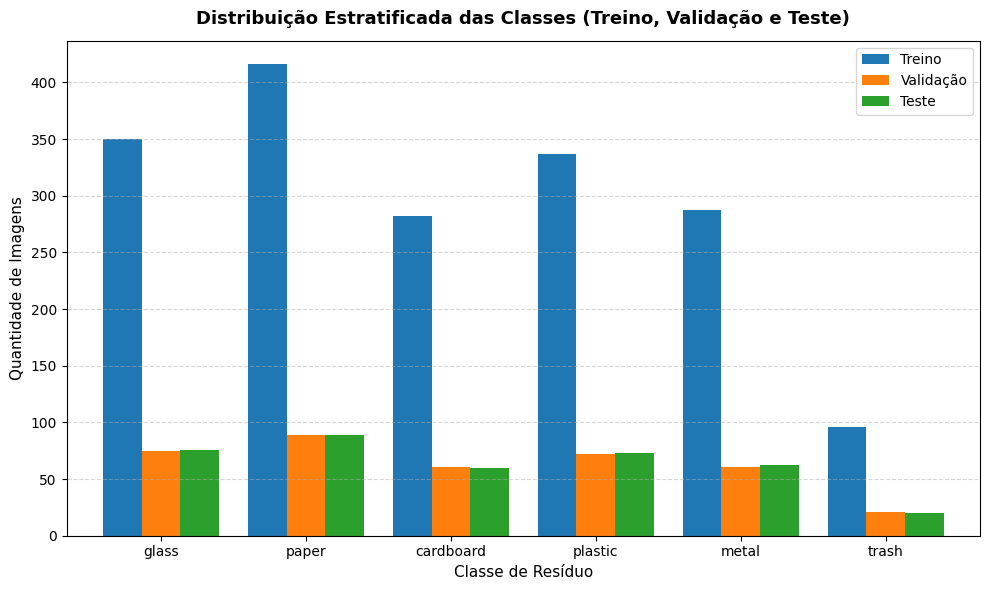

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
df_splits[['Treino', 'Validação', 'Teste']].plot(
    kind='bar',
    ax=ax,
    color=['#1f77b4', '#ff7f0e', '#2ca02c'],
    width=0.8
)
ax.set_title('Distribuição Estratificada das Classes (Treino, Validação e Teste)', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Quantidade de Imagens', fontsize=11)
ax.set_xlabel('Classe de Resíduo', fontsize=11)
ax.set_xticklabels(CLASS_NAMES, rotation=0)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'results' / 'dataset_distribution.png', dpi=300)
plt.show()

## 3. Visualização de Amostras por Classe (ao menos duas de cada classe)

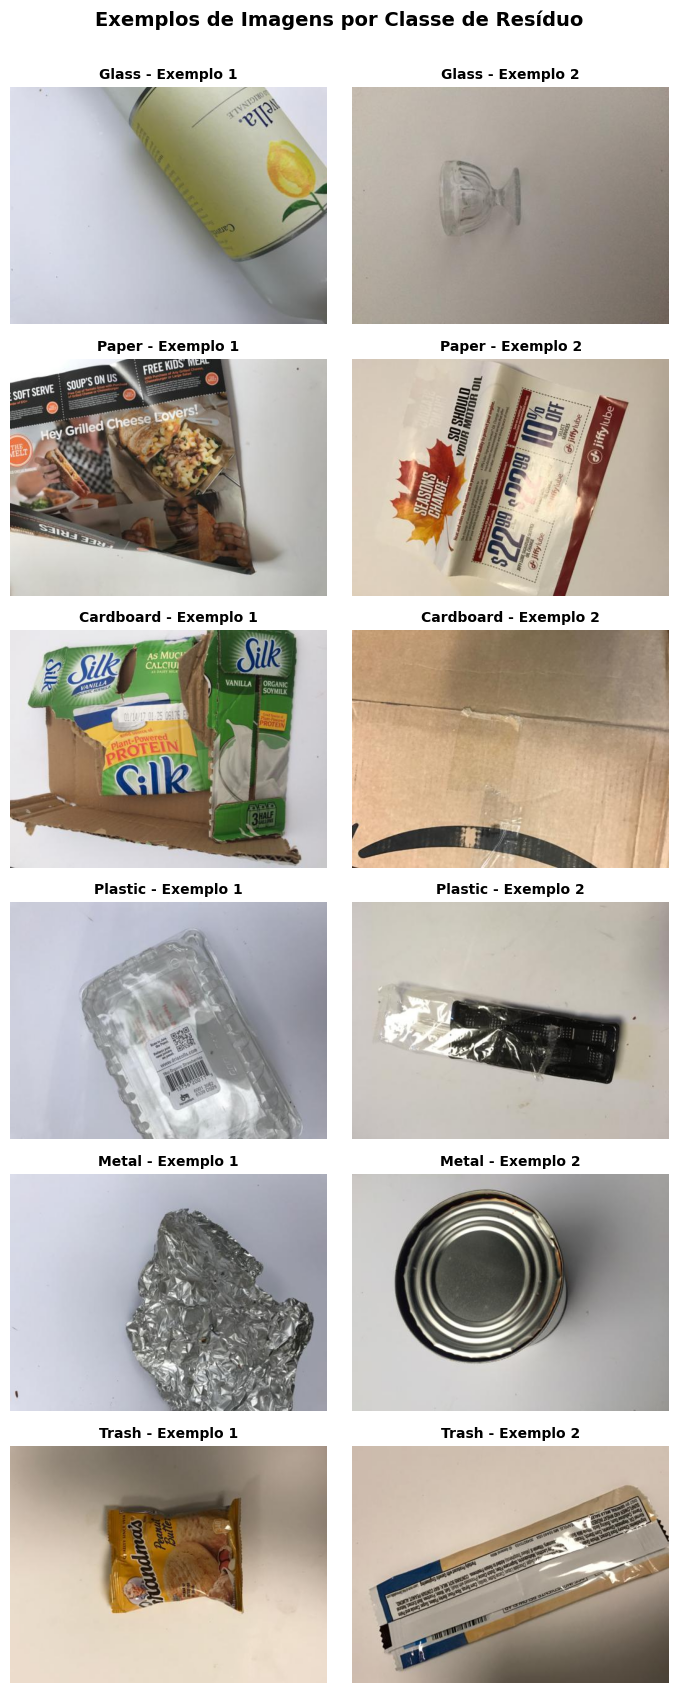

In [5]:
fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(7, 2.8 * len(CLASS_NAMES)))
for i, cls in enumerate(CLASS_NAMES):
    samples = [s['path'] for s in splits['train'] if s['class_name'] == cls][:2]
    for j, path in enumerate(samples):
        img = Image.open(path).convert('RGB')
        axes[i, j].imshow(img)
        axes[i, j].set_title(f"{cls.capitalize()} - Exemplo {j+1}", fontsize=10, fontweight='bold')
        axes[i, j].axis('off')
plt.suptitle('Exemplos de Imagens por Classe de Resíduo', fontsize=14, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'results' / 'class_samples.png', dpi=300)
plt.show()

## 4. Uma Mesma Imagem nas Três Resoluções do Estudo
Resoluções: 128 × 96, 256 × 192 e 512 × 384 (largura × altura).

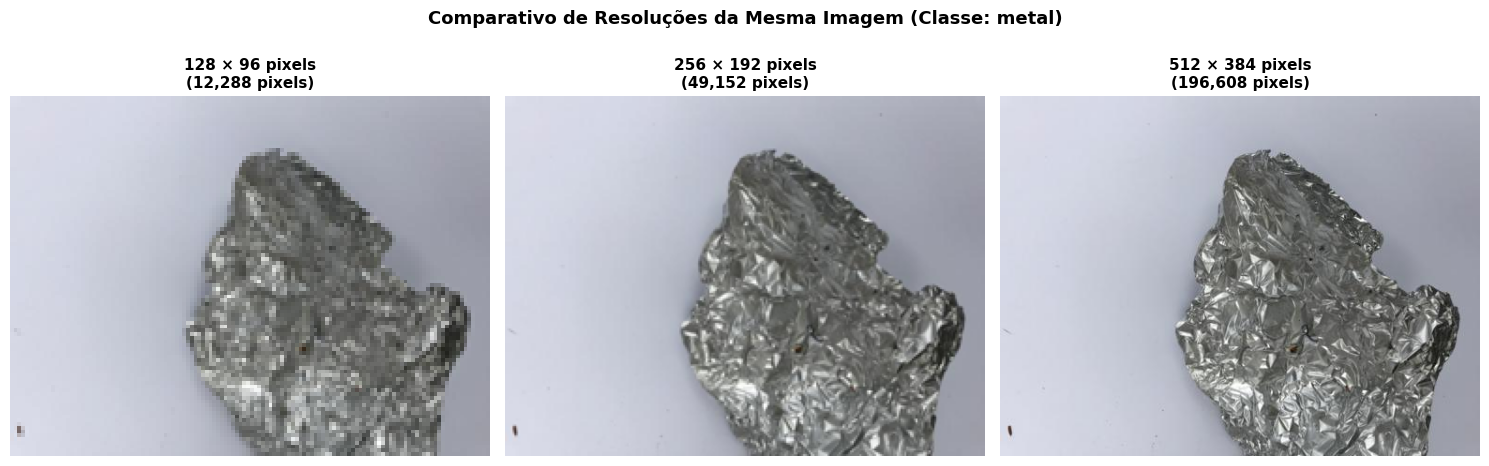

In [6]:
sample_path = splits['train'][0]['path']
orig_img = Image.open(sample_path).convert('RGB')
resolutions = [(128, 96), (256, 192), (512, 384)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (w, h) in zip(axes, resolutions):
    resized = orig_img.resize((w, h))
    ax.imshow(resized)
    ax.set_title(f"{w} × {h} pixels\n({w*h:,} pixels)", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle(f"Comparativo de Resoluções da Mesma Imagem (Classe: {splits['train'][0]['class_name']})", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'results' / 'resolution_samples.png', dpi=300)
plt.show()